**Setup**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 82 (delta 28), reused 64 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 14.03 MiB | 19.33 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


In [2]:
import torch, numpy as np
from src.data import *
from src.scoring import *
from src.metrics import *

**Cellule 2 : imports et utilitaires**

In [3]:
import io, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
import torch.nn.functional as F, torch.nn.utils.prune as prune
from torch.utils.data import DataLoader
from src.data import *
from src.scoring import *
from src.metrics import evaluate

SIGMA = 4
CATS_RUN = CATEGORIES                  # mets ["screw"] si tu n'as pas de GPU
LAT_CAT = "screw"                      # catégorie utilisée pour mesurer la latence CPU
RES_DIR = f"{REPO}/results"; os.makedirs(RES_DIR, exist_ok=True)

def prune_linear(model, amount):
    for mod in model.modules():
        if isinstance(mod, nn.Linear):
            prune.l1_unstructured(mod, "weight", amount=amount); prune.remove(mod, "weight")

def size_mb(model, bank):
    buf = io.BytesIO(); torch.save(model.state_dict(), buf)
    return buf.getbuffer().nbytes / 1e6, bank.numel() * bank.element_size() / 1e6

**Cellule 3 : détecteur configurable**

In [4]:
class EdgeDino:
    def __init__(self, arch="dino_vits8", quant=False, prune_amt=0.0, bank_ratio=1.0, dev=device):
        m = torch.hub.load("facebookresearch/dino:main", arch, trust_repo=True).eval()
        if prune_amt > 0: prune_linear(m, prune_amt)
        if quant:
            m = torch.ao.quantization.quantize_dynamic(m, {nn.Linear}, dtype=torch.qint8)
            self.model_dev = "cpu"                      # l'INT8 dynamique tourne sur CPU
        else:
            self.model_dev = dev
        self.model, self.bank_dev, self.bank_ratio = m.to(self.model_dev), dev, bank_ratio
        self.grid = 224 // (8 if arch.endswith("8") else 16); self.bank = None

    @torch.no_grad()
    def feats(self, x):
        return self.model.get_intermediate_layers(x.to(self.model_dev), n=1)[0][:, 1:]

    @torch.no_grad()
    def fit(self, loader):                              # la banque est reconstruite avec CE modèle compressé
        f = torch.cat([self.feats(x).flatten(0, 1).to(self.bank_dev) for x, _, _ in loader])
        if self.bank_ratio < 1:
            idx = torch.randperm(len(f), generator=torch.Generator().manual_seed(0))
            f = f[idx[: int(len(f) * self.bank_ratio)].to(self.bank_dev)]
        self.bank = f

    @torch.no_grad()
    def knn(self, q):
        return torch.cat([torch.cdist(q[i:i + 1024], self.bank).min(1).values
                          for i in range(0, len(q), 1024)])

    @torch.no_grad()
    def map(self, x):
        f = self.feats(x); B = f.shape[0]
        d = self.knn(f.flatten(0, 1).to(self.bank_dev)).reshape(B, 1, self.grid, self.grid)
        return F.interpolate(d, size=(224, 224), mode="bilinear", align_corners=False)[:, 0].cpu()

    def to_cpu(self):                                   # pour la mesure de latence
        self.model = self.model.cpu(); self.bank = self.bank.cpu()
        self.model_dev = self.bank_dev = "cpu"

def latency_cpu(inst, x1, n=15, warm=3):
    tv, tk = [], []
    for i in range(warm + n):
        t0 = time.perf_counter(); f = inst.feats(x1); t1 = time.perf_counter()
        inst.knn(f.flatten(0, 1)); t2 = time.perf_counter()
        if i >= warm: tv.append(t1 - t0); tk.append(t2 - t1)
    return 1000 * np.mean(tv), 1000 * np.mean(tk)

**Cellule 4 : grand run**

In [5]:
VARIANTS = {
    "FP32 (réf.)":                    dict(arch="dino_vits8"),
    "INT8 dynamique":                 dict(arch="dino_vits8", quant=True),
    "Banque 25 %":                    dict(arch="dino_vits8", bank_ratio=0.25),
    "Banque 10 %":                    dict(arch="dino_vits8", bank_ratio=0.10),
    "ViT-S/16":                       dict(arch="dino_vits16"),
    "ViT-S/16 + INT8 + banque 25 %":  dict(arch="dino_vits16", quant=True, bank_ratio=0.25),
    "Pruning 30 %":                   dict(arch="dino_vits8", prune_amt=0.3),
    "Pruning 50 %":                   dict(arch="dino_vits8", prune_amt=0.5),
}
CSV = f"{CKPT_DIR}/t12_edge_partial.csv"                 # sur Drive : reprise possible si la session coupe
done = set(map(tuple, pd.read_csv(CSV)[["variant", "category"]].values)) if os.path.exists(CSV) else set()

for vname, cfg in VARIANTS.items():
    inst = EdgeDino(**cfg)
    for cat in CATS_RUN:
        if (vname, cat) in done: continue
        t0 = time.time()
        tr, _ = list_train_val(DATA_ROOT, cat)
        mk = lambda items: MVTecDataset(items, 224, imagenet_norm=True)
        inst.fit(DataLoader(mk(tr), batch_size=16, shuffle=False))
        maps, y, masks = predict_maps(inst.map, mk(list_test(DATA_ROOT, cat)), batch_size=8, device=device)
        res = evaluate(y, masks, maps, sigma=SIGMA)
        w_mb, b_mb = size_mb(inst.model, inst.bank)
        row = dict(variant=vname, category=cat, img_auroc=res["img_auroc"], pix_auroc=res["pix_auroc"],
                   model_mb=w_mb, bank_mb=b_mb, total_mb=w_mb + b_mb, lat_vit_ms=np.nan, lat_knn_ms=np.nan)
        if cat == LAT_CAT:                                # latence CPU, 1 image à la fois
            x1 = mk(list_test(DATA_ROOT, cat))[0][0][None]
            inst.to_cpu(); row["lat_vit_ms"], row["lat_knn_ms"] = latency_cpu(inst, x1)
            inst = EdgeDino(**cfg); inst.fit(DataLoader(mk(tr), batch_size=16))   # remise en état après to_cpu
        pd.DataFrame([row]).to_csv(CSV, mode="a", header=not os.path.exists(CSV), index=False)
        print(f"{vname:32s} {cat:7s} img {row['img_auroc']:.3f} pix {row['pix_auroc']:.3f} "
              f"| {row['total_mb']:.0f} Mo | {time.time()-t0:.0f}s")

Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall8_pretrain/dino_deitsmall8_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall8_pretrain.pth


100%|██████████| 82.7M/82.7M [00:01<00:00, 57.2MB/s]
Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main
/tmp/ipykernel_915/1999220072.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  m = torch.ao.quantization.quantize_dynamic(m, {nn.Linear}, dtype=torch.qint8)
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWa

Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall16_pretrain/dino_deitsmall16_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall16_pretrain.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 292MB/s]
Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main
Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main
Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main


**Cellule 5 : tableau récapitulatif et figure**

,img_auroc,pix_auroc,total_mb,model_mb,bank_mb,lat_vit_ms,lat_knn_ms,lat_total_ms
variant,,,,,,,,
FP32 (réf.),0.974,0.990,351.664,86.735,264.929,669.557,2538.269,3207.826
INT8 dynamique,0.972,0.990,287.995,23.066,264.929,582.474,2502.466,3084.940
Banque 25 %,0.960,0.988,152.967,86.735,66.232,621.796,583.888,1205.684
Banque 10 %,0.949,0.987,113.227,86.735,26.492,626.153,225.224,851.377
ViT-S/16,0.945,0.984,152.949,86.716,66.232,111.946,187.709,299.655
ViT-S/16 + INT8 + banque 25 %,0.892,0.979,39.606,23.048,16.558,96.795,31.898,128.694
Pruning 30 %,0.977,0.990,351.664,86.735,264.929,626.740,2394.391,3021.131
Pruning 50 %,0.978,0.988,351.664,86.735,264.929,589.427,2407.132,2996.559


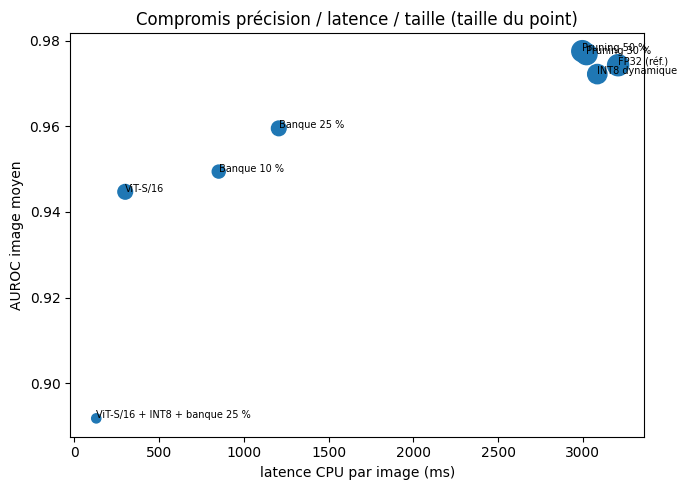

In [6]:
d = pd.read_csv(CSV)
summary = d.groupby("variant", sort=False).agg(
    img_auroc=("img_auroc", "mean"), pix_auroc=("pix_auroc", "mean"),
    total_mb=("total_mb", "mean"), model_mb=("model_mb", "mean"), bank_mb=("bank_mb", "mean"),
    lat_vit_ms=("lat_vit_ms", "mean"), lat_knn_ms=("lat_knn_ms", "mean"))
summary["lat_total_ms"] = summary.lat_vit_ms + summary.lat_knn_ms
summary.round(3).to_csv(f"{RES_DIR}/t12_edge.csv"); d.to_csv(f"{RES_DIR}/t12_edge_per_category.csv", index=False)
display(summary.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(summary.lat_total_ms, summary.img_auroc, s=summary.total_mb * 0.6 + 20)
for v, r in summary.iterrows(): ax.annotate(v, (r.lat_total_ms, r.img_auroc), fontsize=7)
ax.set_xlabel("latence CPU par image (ms)"); ax.set_ylabel("AUROC image moyen")
ax.set_title("Compromis précision / latence / taille (taille du point)")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/t12_tradeoff.png", dpi=150); plt.show()

In [7]:
%cd /content/anomaly-mvtec
!ls results | grep t12_
!zip -o /content/results07.zip results/t12_*
from google.colab import files
files.download("/content/results07.zip")

/content/anomaly-mvtec
t12_edge.csv
t12_edge_per_category.csv
t12_tradeoff.png
  adding: results/t12_edge.csv (deflated 44%)
  adding: results/t12_edge_per_category.csv (deflated 58%)
  adding: results/t12_tradeoff.png (deflated 15%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>